# Phần 1.4 — MagnetDB: hệ sinh thái torrent trên mạng DHT

**MagnetDB** (Seidenberger, Pursell & Maiti, ICWSM 2025; CC-BY 4.0) là bộ dữ liệu học thuật do một crawler "nghe" mạng BitTorrent DHT thu thập từ 12/2018 đến 9/2024: **28,6 triệu torrent** và **950 triệu file**. Phần này nhìn toàn bộ mạng — mọi loại nội dung, chưa lọc riêng phim.

Dữ liệu chuẩn bị bởi `src/10_extract_magnetdb_overview.py`: mọi torrent (tên, dung lượng, thời điểm phát hiện), **mẫu ngẫu nhiên 1% bảng files** (9,5 triệu file) để biết định dạng, và số file của mỗi torrent.

Lưu ý: dự án chỉ dùng **metadata** (tên, dung lượng, thời gian), không tải nội dung. Thời gian là lúc crawler **phát hiện** torrent, không phải lúc torrent được tạo. Biểu đồ lưu vào `plots/4_magnetdb/`.

In [1]:
# Tìm thư mục gốc dự án (chứa src/viz_style.py) để import phong cách biểu đồ dùng chung
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "viz_style.py").exists())
sys.path.insert(0, str(ROOT / "src"))
%matplotlib inline

## Nạp dữ liệu

In [2]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

import viz_style as V

V.setup()
FOLDER = "4_magnetdb"
SRC = "Nguồn: MagnetDB (Seidenberger và cộng sự, 2025)."
P = lambda name: (V.DC / name).as_posix()

con = duckdb.connect()
con.execute(f"CREATE VIEW tor AS SELECT * FROM read_parquet('{P('mdb_torrents_all.parquet')}')")
fs = duckdb.sql(f"SELECT * FROM read_parquet('{P('mdb_files_sample.parquet')}')").df()
n_tor = con.execute("SELECT count(*) FROM tor").fetchone()[0]
print(f"{n_tor:,} torrent; mẫu {len(fs):,} file")

CATS = {
    "Video": "mkv mp4 avi ts m2ts wmv mov mpg mpeg m4v vob flv webm rmvb 3gp",
    "Âm thanh": "mp3 flac wav m4a aac ogg ape wma opus dsf dff",
    "Hình ảnh": "jpg jpeg png gif bmp webp heic tif tiff psd",
    "Sách & tài liệu": "pdf epub mobi azw3 djvu doc docx cbz cbr chm fb2 rtf txt",
    "Phần mềm & game": "exe dll msi apk dmg cab pak bin iso nsp xci sys so jar",
    "Nén": "zip rar 7z gz tar xz",
    "Phụ đề & mô tả": "srt ass sub idx nfo sfv md5 url lnk",
}
EXT2CAT = {e: c for c, exts in CATS.items() for e in exts.split()}
fs["cat"] = fs["ext"].map(EXT2CAT).fillna("Khác")
fs.loc[fs["ext"].fillna("").str.fullmatch(r"r\d\d|\d{3}"), "cat"] = "Nén"   # .r00, .001 (nén chia phần)
ORDER = list(CATS) + ["Khác"]
COLORS = dict(zip(ORDER, V.CAT[:7] + [V.OTHER]))

28,606,694 torrent; mẫu 9,500,000 file


## 1. Mạng DHT chia sẻ những gì?

  wrote plots\4_magnetdb\01_content_sunburst.png


WindowsPath('D:/dulieulon/plots/4_magnetdb/01_content_sunburst.png')

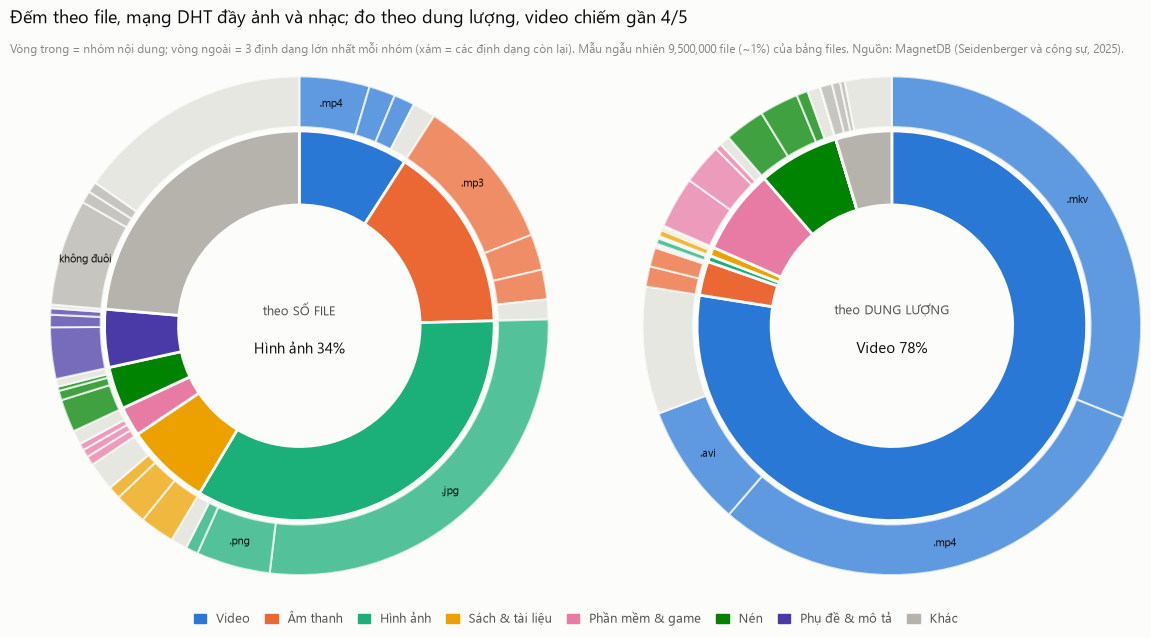

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6.4))
for ax, (weight, label) in zip(axes, [(None, "theo SỐ FILE"), ("size", "theo DUNG LƯỢNG")]):
    w = fs[weight] if weight else pd.Series(1, index=fs.index)
    by_cat = w.groupby(fs["cat"]).sum().reindex(ORDER).fillna(0)
    share = by_cat / by_cat.sum()
    ax.pie(share, colors=[COLORS[c] for c in ORDER], radius=1.0, startangle=90, counterclock=False,
           wedgeprops=dict(width=0.38, edgecolor=V.SURFACE, linewidth=2))
    # vòng ngoài: 3 phần mở rộng lớn nhất trong mỗi nhóm, phần còn lại của nhóm = nhạt
    outer_vals, outer_cols, outer_lbl = [], [], []
    for c in ORDER:
        sub = w[fs["cat"] == c].groupby(fs.loc[fs["cat"] == c, "ext"].fillna("?")).sum().sort_values(ascending=False)
        top = sub.head(3)
        for e, v in top.items():
            outer_vals.append(v); outer_cols.append(COLORS[c])
            outer_lbl.append("không đuôi" if e == "?" else f".{e}")
        if sub.iloc[3:].sum() > 0:
            outer_vals.append(sub.iloc[3:].sum()); outer_cols.append(V.GRID); outer_lbl.append("")
    outer = np.array(outer_vals) / sum(outer_vals)
    wedges, _ = ax.pie(outer, colors=outer_cols, radius=1.28, startangle=90, counterclock=False,
                       wedgeprops=dict(width=0.26, edgecolor=V.SURFACE, linewidth=1.5, alpha=0.75))
    for wdg, lbl, frac in zip(wedges, outer_lbl, outer):
        if lbl and frac >= 0.035:
            ang = np.deg2rad((wdg.theta1 + wdg.theta2) / 2)
            ax.text(1.15 * np.cos(ang), 1.15 * np.sin(ang), lbl, ha="center", va="center",
                    fontsize=8, color=V.INK)
    big = share.idxmax()
    ax.text(0, 0.08, label, ha="center", va="center", fontsize=9, color=V.INK2)
    ax.text(0, -0.12, f"{big} {share[big]:.0%}", ha="center", va="center", fontsize=11, color=V.INK)
    ax.set_aspect("equal")
handles = [plt.Rectangle((0, 0), 1, 1, color=COLORS[c]) for c in ORDER]
fig.legend(handles, ORDER, ncol=8, loc="lower center", handlelength=1, columnspacing=1.2)
V.titles(fig, "Đếm theo file, mạng DHT đầy ảnh và nhạc; đo theo dung lượng, video chiếm gần 4/5",
         f"Vòng trong = nhóm nội dung; vòng ngoài = 3 định dạng lớn nhất mỗi nhóm (xám = các định dạng còn lại). "
         f"Mẫu ngẫu nhiên {len(fs):,} file (~1%) của bảng files. {SRC}")
fig.subplots_adjust(bottom=0.1)
V.save(fig, FOLDER, "01_content_sunburst")

**Nhận xét.** Hai cách đếm cho hai bức tranh khác hẳn: **theo số file**, hình ảnh (34%, chủ yếu `.jpg`) và âm thanh (`.mp3`) chiếm nhiều nhất; **theo dung lượng**, **video chiếm ~78%** (`.mkv`, `.mp4`, `.avi`). Một bộ phim 2 GB "nặng" bằng hàng nghìn bức ảnh — nên mạng DHT về bản chất là mạng **phân phối video**, dù số file video không nhiều.

## 2. Torrent thường nặng bao nhiêu?

  wrote plots\4_magnetdb\02_size_magic_numbers.png


WindowsPath('D:/dulieulon/plots/4_magnetdb/02_size_magic_numbers.png')

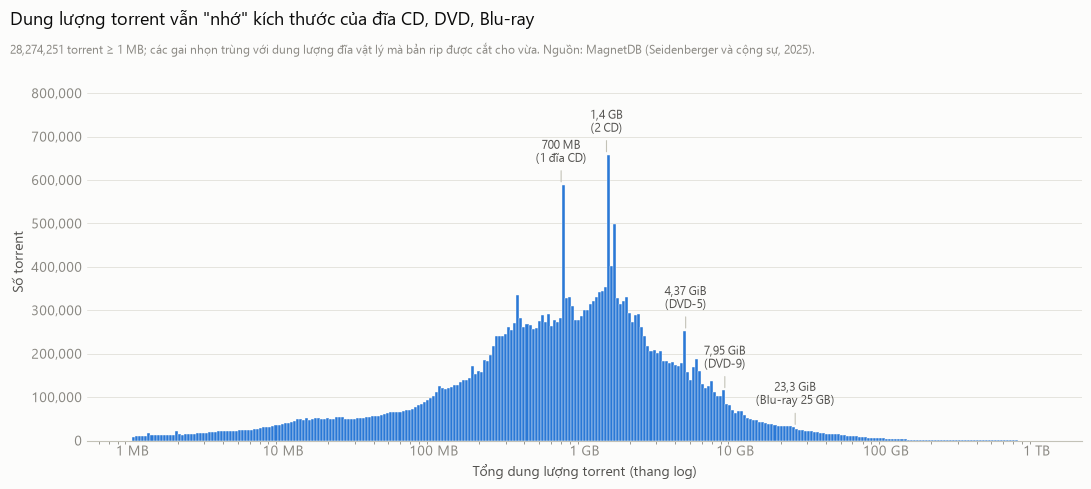

In [4]:
sizes = con.execute("SELECT total_size FROM tor WHERE total_size >= 1e6").df()["total_size"]
bins = np.logspace(6, 12, 300)
fig, ax = plt.subplots(figsize=(11, 5))
V.style_axes(ax)
cnt, edges, _ = ax.hist(sizes, bins=bins, color=V.BLUE, edgecolor=V.SURFACE, linewidth=0.3)
MAGIC = [(7.0e8, "700 MB\n(1 đĩa CD)"), (1.4e9, "1,4 GB\n(2 CD)"), (4.37 * 2**30, "4,37 GiB\n(DVD-5)"),
         (7.95 * 2**30, "7,95 GiB\n(DVD-9)"), (23.3 * 2**30, "23,3 GiB\n(Blu-ray 25 GB)")]
for x, lbl in MAGIC:
    i = np.searchsorted(edges, x) - 1
    y = cnt[max(i - 1, 0):i + 2].max()
    ax.annotate(lbl, xy=(x, y), xytext=(0, 14), textcoords="offset points", ha="center", va="bottom",
                color=V.INK2, fontsize=8.5, arrowprops=dict(arrowstyle="-", color=V.AXIS, linewidth=0.8))
ax.set_xscale("log")
ax.set_xticks([1e6, 1e7, 1e8, 1e9, 1e10, 1e11, 1e12])
ax.set_xticklabels(["1 MB", "10 MB", "100 MB", "1 GB", "10 GB", "100 GB", "1 TB"])
ax.yaxis.set_major_formatter(FuncFormatter(V.fmt_int))
ax.set_ylim(0, cnt.max() * 1.25)
ax.set_xlabel("Tổng dung lượng torrent (thang log)")
ax.set_ylabel("Số torrent")
V.titles(fig, "Dung lượng torrent vẫn \"nhớ\" kích thước của đĩa CD, DVD, Blu-ray",
         f"{len(sizes):,} torrent ≥ 1 MB; các gai nhọn trùng với dung lượng đĩa vật lý mà bản rip được cắt cho vừa. {SRC}")
V.save(fig, FOLDER, "02_size_magic_numbers")

**Nhận xét.** Phân bố có đỉnh quanh 1 GB, nhưng nổi bật là các **gai nhọn** đúng ở **700 MB (1 đĩa CD), 1,4 GB (2 CD), 4,37 GiB (DVD-5), 7,95 GiB (DVD-9)**. Đây là "di sản" của thời đĩa vật lý: các nhóm phát hành vẫn nén phim cho vừa dung lượng đĩa dù ngày nay không còn ai ghi đĩa — một quy ước văn hóa còn sót lại trong dữ liệu.

## 3. Crawler thu thập có đều không?

  wrote plots\4_magnetdb\03_crawler_coverage.png


WindowsPath('D:/dulieulon/plots/4_magnetdb/03_crawler_coverage.png')

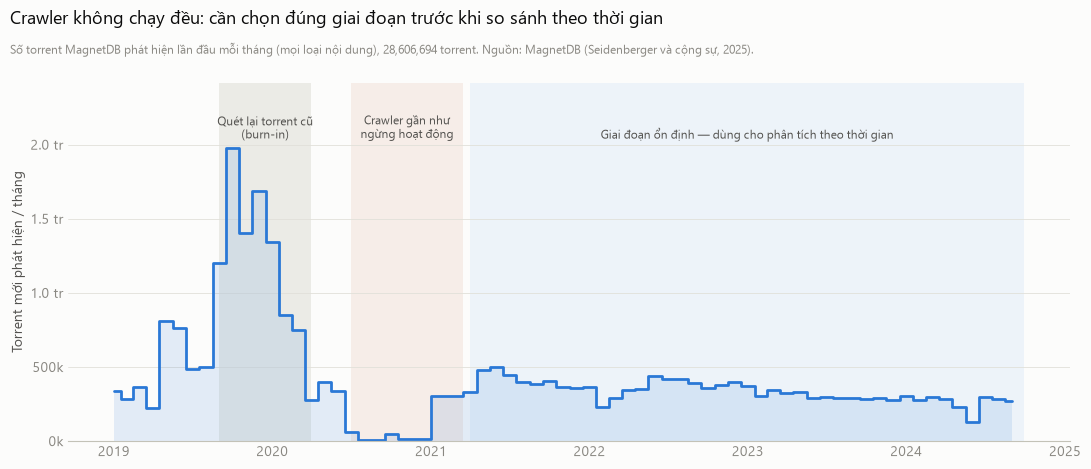

In [5]:
m = con.execute("""SELECT date_trunc('month', discovered_at_utc) AS m, count(*) AS n FROM tor
                   WHERE discovered_at_utc BETWEEN '2018-12-01' AND '2024-09-30' GROUP BY 1 ORDER BY 1""").df()
fig, ax = plt.subplots(figsize=(11, 4.8))
V.style_axes(ax)
ax.fill_between(m["m"], m["n"], color=V.BLUE, alpha=0.12, linewidth=0, step="mid")
ax.step(m["m"], m["n"], color=V.BLUE, where="mid")
spans = [("2019-09-01", "2020-03-31", "Quét lại torrent cũ\n(burn-in)"),
         ("2020-07-01", "2021-03-15", "Crawler gần như\nngừng hoạt động"),
         ("2021-04-01", "2024-09-29", "Giai đoạn ổn định — dùng cho phân tích theo thời gian")]
ymax = m["n"].max()
for (a, b, lbl), shade in zip(spans, [V.GRID, "#f3e3dc", "#e3edf9"]):
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=shade, alpha=0.6, linewidth=0, zorder=0)
    ax.text(pd.Timestamp(a) + (pd.Timestamp(b) - pd.Timestamp(a)) / 2, ymax * 1.02, lbl, ha="center",
            va="bottom", color=V.INK2, fontsize=8.5)
ax.set_ylim(0, ymax * 1.22)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1e6:.1f} tr" if v >= 1e6 else f"{v / 1e3:.0f}k"))
ax.set_ylabel("Torrent mới phát hiện / tháng")
V.titles(fig, "Crawler không chạy đều: cần chọn đúng giai đoạn trước khi so sánh theo thời gian",
         f"Số torrent MagnetDB phát hiện lần đầu mỗi tháng (mọi loại nội dung), {n_tor:,} torrent. {SRC}")
V.save(fig, FOLDER, "03_crawler_coverage")

**Nhận xét.** **Không.** 9/2019–3/2020 số torrent tăng vọt (crawler quét lại torrent cũ — *burn-in*), 7/2020–3/2021 gần như ngừng. Chỉ **4/2021–9/2024** là ổn định (~300–450 nghìn torrent/tháng). Mọi phân tích theo thời gian trong dự án chỉ dùng giai đoạn này; đây là bước **kiểm tra chất lượng dữ liệu** quan trọng trước khi kết luận bất cứ điều gì về xu hướng.

## 4. Nhìn từng ngày thì sao?

  wrote plots\4_magnetdb\04_calendar_heatmap.png


WindowsPath('D:/dulieulon/plots/4_magnetdb/04_calendar_heatmap.png')

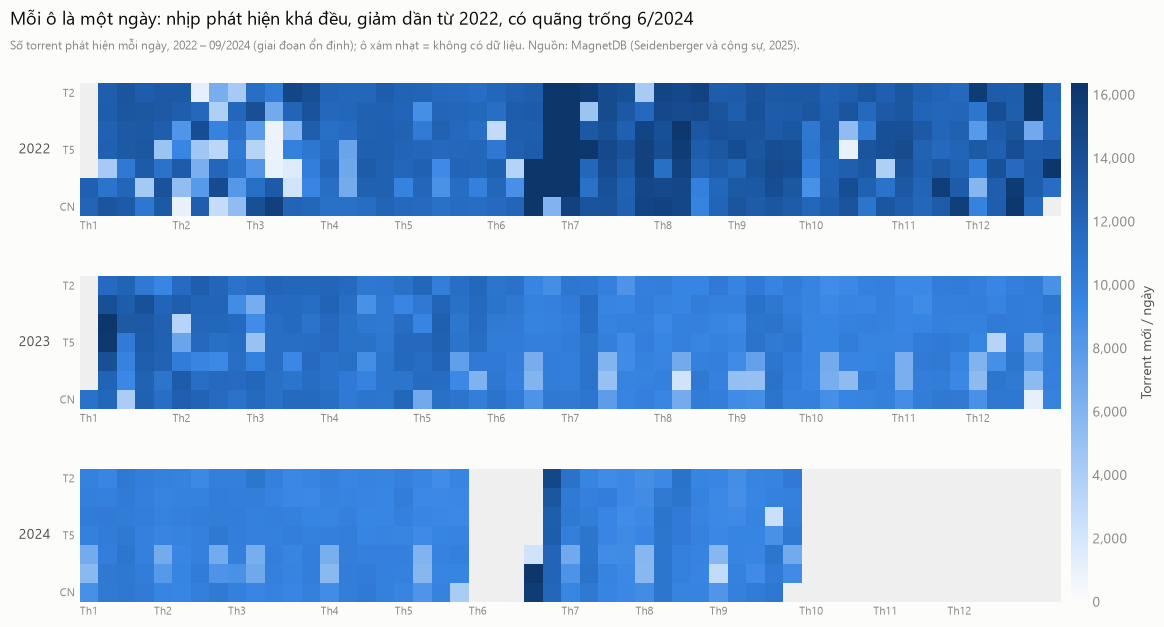

In [6]:
d = con.execute("""SELECT discovered_at_utc::DATE AS d, count(*) AS n FROM tor
                   WHERE discovered_at_utc BETWEEN '2022-01-01' AND '2024-09-29' GROUP BY 1""").df()
d["d"] = pd.to_datetime(d["d"])
years = [2022, 2023, 2024]
fig = plt.figure(figsize=(12, 6.4))
gs = fig.add_gridspec(len(years), 2, width_ratios=[60, 1], hspace=0.45, wspace=0.02)
axes = [fig.add_subplot(gs[i, 0]) for i in range(len(years))]
cax = fig.add_subplot(gs[:, 1])
vmax = d["n"].quantile(0.98)
for ax, y in zip(axes, years):
    full = pd.DataFrame({"d": pd.date_range(f"{y}-01-01", f"{y}-12-31")}).merge(d, how="left")
    full["wk"] = ((full["d"] - pd.Timestamp(f"{y}-01-01")).dt.days + pd.Timestamp(f"{y}-01-01").weekday()) // 7
    full["dow"] = full["d"].dt.weekday
    grid = full.pivot(index="dow", columns="wk", values="n")
    im = ax.imshow(grid, cmap=V.SEQ, vmin=0, vmax=vmax, aspect="auto")
    ax.imshow(np.where(grid.isna(), 1, np.nan), cmap="Greys", vmin=0, vmax=8, aspect="auto")
    ax.set_yticks([0, 3, 6])
    ax.set_yticklabels(["T2", "T5", "CN"], color=V.MUTED, fontsize=8)
    month_starts = [((pd.Timestamp(f"{y}-{mm:02d}-01") - pd.Timestamp(f"{y}-01-01")).days
                     + pd.Timestamp(f"{y}-01-01").weekday()) // 7 for mm in range(1, 13)]
    ax.set_xticks(month_starts)
    ax.set_xticklabels([f"Th{mm}" for mm in range(1, 13)], color=V.MUTED, fontsize=8)
    ax.set_ylabel(str(y), color=V.INK2, rotation=0, labelpad=18, va="center")
    for s in ax.spines.values():
        s.set_visible(False)
cb = fig.colorbar(im, cax=cax)
cb.outline.set_visible(False)
cb.set_label("Torrent mới / ngày", color=V.INK2)
cb.ax.yaxis.set_major_formatter(FuncFormatter(V.fmt_int))
fig.text(0.012, 0.975, "Mỗi ô là một ngày: nhịp phát hiện khá đều, giảm dần từ 2022, có quãng trống 6/2024",
         color=V.INK, fontsize=13, va="top")
fig.text(0.012, 0.93, f"Số torrent phát hiện mỗi ngày, 2022 – 09/2024 (giai đoạn ổn định); ô xám nhạt = không có dữ liệu. {SRC}",
         color=V.MUTED, fontsize=8.5, va="top")
fig.subplots_adjust(left=0.07, right=0.91, top=0.86, bottom=0.05)
V.save(fig, FOLDER, "04_calendar_heatmap")

**Nhận xét.** Lịch nhiệt cho thấy nhịp khá đều trong tuần, **giảm dần từ 2022 sang 2024** (màu nhạt dần), vài ngày đột biến (đầu tháng 7/2022) và **quãng trống gần 1 tháng (6/2024)** khi crawler ngừng. Những chi tiết này không thấy được trên biểu đồ theo tháng.

## 5. Giờ nào trong tuần sôi động nhất?

  wrote plots\4_magnetdb\05_hour_weekday.png


WindowsPath('D:/dulieulon/plots/4_magnetdb/05_hour_weekday.png')

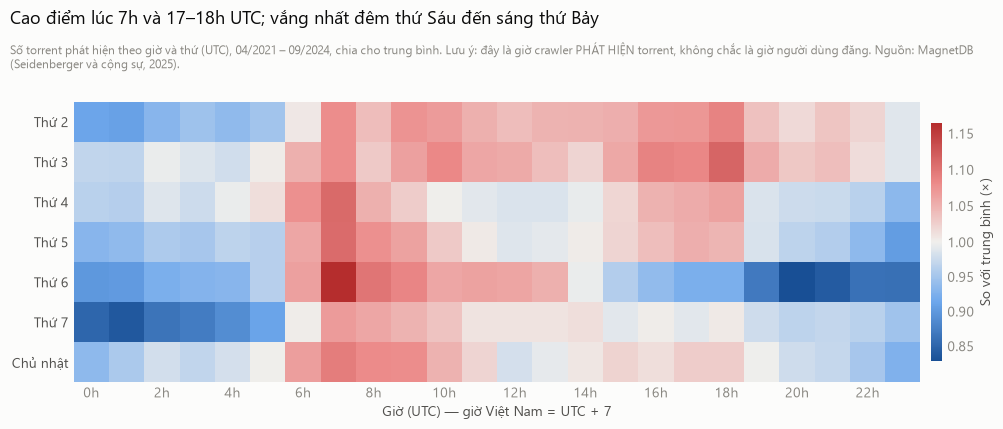

In [7]:
hw = con.execute("""SELECT isodow(discovered_at_utc) - 1 AS dow, hour(discovered_at_utc) AS h, count(*) AS n
                    FROM tor WHERE discovered_at_utc BETWEEN '2021-04-01' AND '2024-09-29' GROUP BY 1, 2""").df()
grid = hw.pivot(index="dow", columns="h", values="n")
grid = grid / grid.values.mean()
fig, ax = plt.subplots(figsize=(11, 4.4))
from matplotlib.colors import TwoSlopeNorm
im = ax.imshow(grid, cmap=V.DIV, norm=TwoSlopeNorm(1, grid.values.min(), grid.values.max()), aspect="auto")
ax.set_yticks(range(7))
ax.set_yticklabels(["Thứ 2", "Thứ 3", "Thứ 4", "Thứ 5", "Thứ 6", "Thứ 7", "Chủ nhật"], color=V.INK2)
ax.set_xticks(range(0, 24, 2))
ax.set_xticklabels([f"{h}h" for h in range(0, 24, 2)], color=V.MUTED)
ax.set_xlabel("Giờ (UTC) — giờ Việt Nam = UTC + 7")
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, shrink=0.85, pad=0.01)
cb.outline.set_visible(False)
cb.set_label("So với trung bình (×)", color=V.INK2)
V.titles(fig, "Cao điểm lúc 7h và 17–18h UTC; vắng nhất đêm thứ Sáu đến sáng thứ Bảy",
         f"Số torrent phát hiện theo giờ và thứ (UTC), 04/2021 – 09/2024, chia cho trung bình. Lưu ý: đây là giờ crawler "
         f"PHÁT HIỆN torrent, không chắc là giờ người dùng đăng. {SRC}")
V.save(fig, FOLDER, "05_hour_weekday")

**Nhận xét.** Cao điểm quanh **7h UTC** (14h Việt Nam, sáng châu Âu, chiều tối châu Á) và **17–18h UTC** (tối châu Âu); thấp nhất từ **tối thứ Sáu đến sáng thứ Bảy**. Chênh lệch chỉ ±15% so với trung bình — mạng toàn cầu nên "không bao giờ ngủ". Thận trọng: đây là giờ crawler *phát hiện*, có thể phản ánh cả lịch hoạt động của chính crawler.

## 6. Tên torrent viết bằng ngôn ngữ nào?

  wrote plots\4_magnetdb\06_name_script_waffle.png


WindowsPath('D:/dulieulon/plots/4_magnetdb/06_name_script_waffle.png')

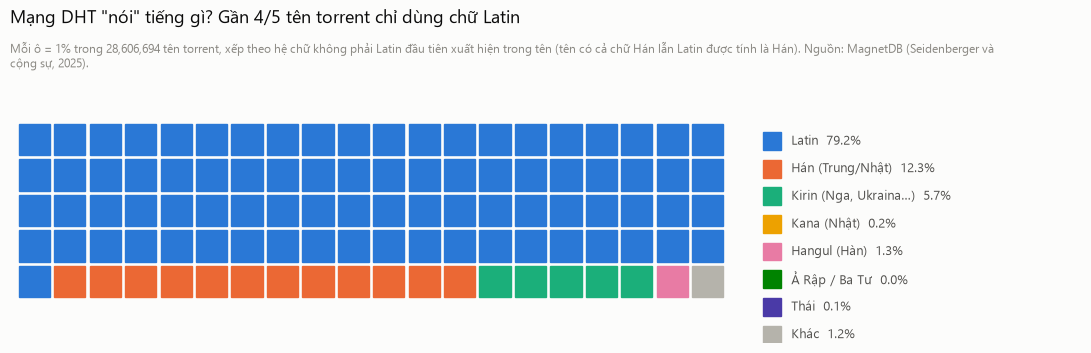

In [8]:
SCRIPTS = [("Latin", None), ("Hán (Trung/Nhật)", "[一-鿿]"), ("Kirin (Nga, Ukraina…)", "[а-яА-ЯёЁіїєґ]"),
           ("Kana (Nhật)", "[぀-ヿ]"), ("Hangul (Hàn)", "[가-힣]"), ("Ả Rập / Ba Tư", "[؀-ۿ]"),
           ("Thái", "[฀-๿]")]
case = "CASE " + " ".join(f"WHEN regexp_matches(name, '{rx}') THEN '{lbl}'" for lbl, rx in SCRIPTS[1:][::-1][::-1]) \
       + " WHEN regexp_matches(name, '[A-Za-z]') THEN 'Latin' ELSE 'Khác' END"
sc = con.execute(f"SELECT {case} AS s, count(*) AS n FROM tor GROUP BY 1").df().set_index("s")["n"]
labels = [l for l, _ in SCRIPTS] + ["Khác"]
sc = sc.reindex(labels).fillna(0)
pct = sc / sc.sum() * 100
cells = np.floor(pct).astype(int)
cells.iloc[cells.argmax()] += 100 - cells.sum()                     # làm tròn để đủ 100 ô
colors = dict(zip(labels, V.CAT[:7] + [V.OTHER]))
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.axis("off")
k = 0
for lbl in labels:
    for _ in range(cells[lbl]):
        r, c = divmod(k, 20)
        ax.add_patch(plt.Rectangle((c, -r), 0.88, 0.88, color=colors[lbl]))
        k += 1
ax.set_xlim(-0.2, 30)
ax.set_ylim(-5.3, 1.1)
ax.set_aspect("equal")
for i, lbl in enumerate(labels):
    y = 0.4 - i * 0.78
    ax.add_patch(plt.Rectangle((21, y - 0.25), 0.5, 0.5, color=colors[lbl]))
    ax.text(21.8, y, f"{lbl}  {pct[lbl]:.1f}%", va="center", color=V.INK2, fontsize=9)
V.titles(fig, "Mạng DHT \"nói\" tiếng gì? Gần 4/5 tên torrent chỉ dùng chữ Latin",
         f"Mỗi ô = 1% trong {n_tor:,} tên torrent, xếp theo hệ chữ không phải Latin đầu tiên xuất hiện trong tên "
         f"(tên có cả chữ Hán lẫn Latin được tính là Hán). {SRC}")
V.save(fig, FOLDER, "06_name_script_waffle")

**Nhận xét.** **~79%** tên chỉ dùng chữ Latin (tiếng Anh và các ngôn ngữ châu Âu), **chữ Hán ~12%** (cộng đồng Trung Quốc rất lớn trên DHT), **chữ Kirin ~6%** (Nga, Ukraina). Hàn, Nhật (kana), Thái, Ả Rập chỉ chiếm phần nhỏ — các cộng đồng này dùng kênh chia sẻ khác.

## 7. Một torrent chứa bao nhiêu file?

  wrote plots\4_magnetdb\07_files_per_torrent_ccdf.png


WindowsPath('D:/dulieulon/plots/4_magnetdb/07_files_per_torrent_ccdf.png')

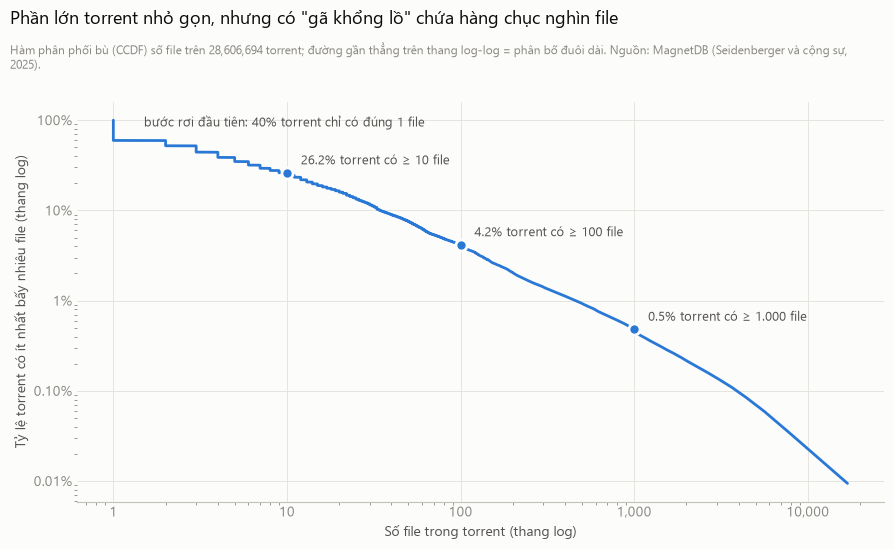

In [9]:
nf = duckdb.sql(f"SELECT n_files FROM read_parquet('{P('mdb_files_per_torrent.parquet')}')").df()["n_files"].values
x = np.sort(nf)
ccdf = 1 - np.arange(len(x)) / len(x)
fig, ax = plt.subplots(figsize=(9, 5.6))
V.style_axes(ax, grid="both")
step = max(len(x) // 4000, 1)
ax.plot(x[::step], ccdf[::step], color=V.BLUE)
one = (nf == 1).mean()
ax.annotate(f"bước rơi đầu tiên: {one:.0%} torrent chỉ có đúng 1 file", xy=(1.5, (nf >= 2).mean()),
            xytext=(0, 10), textcoords="offset points", color=V.INK2, fontsize=9)
for q, lbl in [(10, "≥ 10 file"), (100, "≥ 100 file"), (1000, "≥ 1.000 file")]:
    yi = (nf >= q).mean()
    ax.plot(q, yi, "o", markersize=8, color=V.BLUE, markeredgecolor=V.SURFACE, markeredgewidth=2)
    ax.annotate(f"{yi:.1%} torrent có {lbl}", xy=(q, yi), xytext=(10, 6), textcoords="offset points",
                color=V.INK2, fontsize=9)
ax.set_xscale("log")
ax.set_yscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(V.fmt_int))
ax.set_xlabel("Số file trong torrent (thang log)")
ax.set_ylabel("Tỷ lệ torrent có ít nhất bấy nhiêu file (thang log)")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}" if v >= 0.01 else f"{v:.2%}"))
V.titles(fig, "Phần lớn torrent nhỏ gọn, nhưng có \"gã khổng lồ\" chứa hàng chục nghìn file",
         f"Hàm phân phối bù (CCDF) số file trên {len(nf):,} torrent; đường gần thẳng trên thang log-log = phân bố đuôi dài. {SRC}")
V.save(fig, FOLDER, "07_files_per_torrent_ccdf")

**Nhận xét.** **40% torrent chỉ có đúng 1 file**, 26% có ≥ 10 file, nhưng đuôi kéo dài tới **hơn 10.000 file**. Đường gần thẳng trên thang log-log là dấu hiệu của **phân bố đuôi dài** (gần luật lũy thừa) — giống nhiều hệ thống do con người tạo ra (dung lượng file, lượt xem web, quy mô thành phố).

## Tóm tắt phần MagnetDB

| Khía cạnh | Phát hiện chính |
|---|---|
| Nội dung | Theo dung lượng, ~78% là video; theo số file, ảnh và nhạc nhiều nhất |
| Dung lượng | Gai nhọn ở 700 MB / 1,4 GB / DVD — "di sản" của đĩa vật lý |
| Chất lượng dữ liệu | Crawler không đều; chỉ 4/2021–9/2024 dùng được cho phân tích xu hướng |
| Nhịp thời gian | Cao điểm 7h & 17–18h UTC; vắng nhất cuối tuần |
| Ngôn ngữ | ~79% Latin, ~12% chữ Hán, ~6% Kirin |
| Cấu trúc | 40% torrent 1 file; phân bố số file đuôi dài |